In [3]:
import numpy as np
import os

data_path = "fashion_mnist"

print(os.listdir(data_path))

['Xtr.npy', 'Xte.npy', '.ipynb_checkpoints', 'ytr.npy', 'yte.npy']


In [4]:
X_train = np.load(os.path.join(data_path, "Xtr.npy"))
X_test = np.load(os.path.join(data_path, "Xte.npy"))

y_train = np.load(os.path.join(data_path, "ytr.npy"))
y_test = np.load(os.path.join(data_path, "yte.npy"))

print("Data loaded Successfully")

Data loaded Successfully


In [5]:
print("X_train:", X_train.shape, X_train.dtype)
print("X_test:", X_test.shape, X_test.dtype)

print("y_train:", y_train.shape, y_train.dtype)
print("y_test:", y_test.shape, y_test.dtype)

X_train: (60000, 784) uint8
X_test: (10000, 784) uint8
y_train: (60000,) uint8
y_test: (10000,) uint8


In [6]:
print("Training images:", len(X_train))
print("Testing images:", len(X_test))

print("Training classes:", np.unique(y_train))
print("Testing classes:", np.unique(y_test))

Training images: 60000
Testing images: 10000
Training classes: [0 1 2 3 4 5 6 7 8 9]
Testing classes: [0 1 2 3 4 5 6 7 8 9]


# **STAGE 1 — SET UP AND LOOK AT THE DATA**

**Objectives :-**
- The objective of this project is to classify clothing images using a Multi-Layer perceptron (MLP).

**Dataset Information :-**
- Training Images - 60,000
- Testing Images - 10,000
- Image Dimensions - 28 X 28
- Input Features - 784
- Number of classes - 10

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os


data_path = "fashion_mnist"

# Load training and testing images
X_train_original = np.load(os.path.join(data_path, "Xtr.npy"))
X_test_original = np.load(os.path.join(data_path, "Xte.npy"))

# Load training and testing labels
y_train_original = np.load(os.path.join(data_path, "ytr.npy"))
y_test = np.load(os.path.join(data_path, "yte.npy"))


print("Dataset loaded Successfully")

Dataset loaded Successfully


In [8]:
print("Training Images:", X_train_original.shape)
print("Testing Images:", X_test_original.shape)

print("Training Labels:", y_train_original.shape)
print("Testing Labels:", y_test.shape)

print("Training Classes:", np.unique(y_train_original))
print("Testing Classes:", np.unique(y_test))

Training Images: (60000, 784)
Testing Images: (10000, 784)
Training Labels: (60000,)
Testing Labels: (10000,)
Training Classes: [0 1 2 3 4 5 6 7 8 9]
Testing Classes: [0 1 2 3 4 5 6 7 8 9]


In [9]:
class_name = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Number of Classes:", len(class_name))

Number of Classes: 10


In [10]:
# Split the dataset
from sklearn.model_selection import train_test_split

# Split original training data into training and validation
X_train, X_val, y_train, y_val = train_test_split(X_train_original, y_train_original, test_size=0.20,
                                                 random_state=42, stratify=y_train_original)


# Keep original testing data separate
X_test = X_test_original.copy()


print("Training Set:", X_train.shape, y_train.shape)
print("Validation Set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

Training Set: (48000, 784) (48000,)
Validation Set: (12000, 784) (12000,)
Testing set: (10000, 784) (10000,)


**Feature Scaling / Normalization :-**
- The original pixel value range from 0 to 255.
- We normalize them by dividing every pixel value by 255.
- Formula :- Normalized pixel = original pixel / 255
- After normalization, pixel values range between 0 and 1.
- This helps neural networks train more effectively with consistent input scales.

In [11]:
X_train = X_train.astype(np.float32) / 255.0
X_val = X_val.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
Training Shape: (48000, 784)
Validation Shape: (12000, 784)
Testing Shape: (10000, 784)


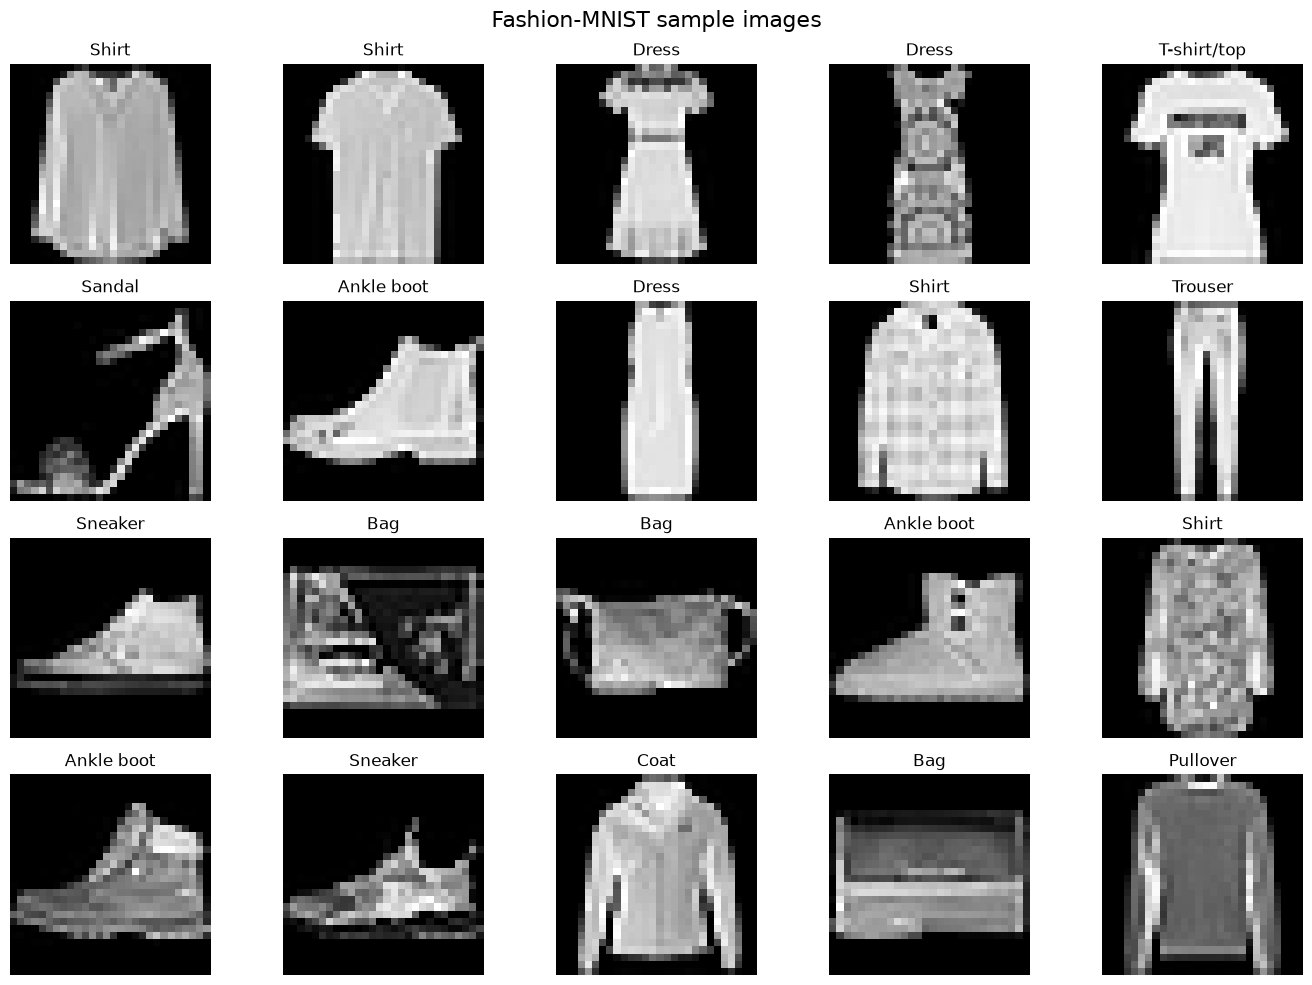

In [12]:
fig, ax = plt.subplots(4, 5, figsize=(14, 10))

for i, ax in enumerate(ax.flat):
    image = X_train[i].reshape(28, 28)
    label = int(y_train[i])
    ax.imshow(image, cmap="gray")
    ax.set_title(class_name[label])
    ax.axis("off")



plt.suptitle("Fashion-MNIST sample images", fontsize=16)
plt.tight_layout()
plt.show()

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings("ignore")

# Convert images into 784 features
X_train_flat = X_train.reshape(len(X_train), 784)
X_val_flat = X_val.reshape(len(X_val), 784)


# Train Logistic regression 
lr_model = LogisticRegression(max_iter=100, solver="saga")
lr_model.fit(X_train_flat, y_train)

# Validation Prediction
lr_prediction = lr_model.predict(X_val_flat)
lr_accuracy = accuracy_score(y_val, lr_prediction)

print("Logistic Regression Validation Accuracy:", lr_accuracy)

Logistic Regression Validation Accuracy: 0.8629166666666667


# **STAGE 2 — ONE PLAIN NETWORK, BUILT CORRECTLY**

In [17]:
# imports and device
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using Device:", device)

# set Random Seed
np.random.seed(42)
torch.manual_seed(42)

Using Device: cpu


In [18]:
def train_model(
    Xtr, ytr, Xv, yv, hidden=256, depth=1, dropout=0.0, weight_decay=0.0, batch_norm=False,
    lr=0.001, epochs=12, batch_size=128, use_scheduler=False, early_stopping=False
):

    # Convert data into pytorch tensors
    Xtr_tensor = torch.tensor(Xtr.reshape(-1, 784), dtype=torch.float32)
    ytr_tensor = torch.tensor(ytr, dtype=torch.long)
    Xv_tensor = torch.tensor(Xv.reshape(-1, 784), dtype=torch.float32).to(device)
    yv_tensor = torch.tensor(yv, dtype=torch.long).to(device)


    # Create training batches
    train_dataset = TensorDataset(Xtr_tensor, ytr_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)


    # Build the MLP
    layers = []
    input_size = 784

    for layer_number in range(depth):
        layers.append(nn.Linear(input_size, hidden))

        if batch_norm:
            layers.append(nn.BatchNorm1d(hidden))

        layers.append(nn.ReLU())

        if dropout > 0:
            layers.append(nn.Dropout(dropout))

        input_size = hidden


    # output layer: 10 classes
    layers.append(nn.Linear(input_size, 10))

    model = nn.Sequential(*layers).to(device)

    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)


    # Optimal Learning rate scheduler
    if use_scheduler:
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

    train_losses = []
    val_losses = []
    val_accuracies = []

    best_val_loss = float("inf")
    best_weights = None
    patience_count = 0


    for epoch in range(epochs):
        # Training
        model.train()
        total_train_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()

            optimizer.step()

            total_train_loss += loss.item() * len(images)

        average_train_loss = total_train_loss / len(train_dataset)

        # validation
        model.eval()

        with torch.no_grad():
            val_outputs = model(Xv_tensor)
            val_loss = criterion(val_outputs, yv_tensor)
            val_predictions = torch.argmax(val_outputs, dim=1)
            val_accuracy = (val_predictions == yv_tensor).float().mean().item()

        train_losses.append(average_train_loss)
        val_losses.append(val_loss.item())
        val_accuracies.append(val_accuracy)


        # save best model weights
        if val_loss.item() < best_val_loss:
            best_val_loss = val_loss.item()
            best_val_accuracy = val_accuracy

            best_weights = {key: value.clone()
                           for key, value in model.state_dict().items()}

            patience_count = 0

        else:
            patience_count += 1


        # Update scheduler
        if use_scheduler:
            scheduler.step()

        print(
            f"Epoch: {epoch + 1}/{epochs} | "
            f"Train Loss: {average_train_loss:.4f} | "
            f"Val Loss: {val_loss.item():.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )


        # Early stopping 
        if early_stopping and patience_count >= 3:
            print("Early stopping activated.")
            break

    # Restore best validation weights
    if best_weights is not None:
        model.load_state_dict(best_weights)


    history = {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "val_accuracy": val_accuracies,
        "best_val_loss": best_val_loss,
        "best_val_accuracy": best_val_accuracy
    }


    return model, history

In [19]:
# Train the plain MLP
plain_model, plain_history = train_model(X_train, y_train, X_val, y_val, hidden=256,
                                        depth=1, lr=0.001, epochs=15)


print("Best MLP Validation Accuracy:", plain_history["best_val_accuracy"])

Epoch: 1/15 | Train Loss: 0.5963 | Val Loss: 0.4449 | Val Accuracy: 0.8453
Epoch: 2/15 | Train Loss: 0.4228 | Val Loss: 0.3878 | Val Accuracy: 0.8614
Epoch: 3/15 | Train Loss: 0.3796 | Val Loss: 0.3632 | Val Accuracy: 0.8714
Epoch: 4/15 | Train Loss: 0.3451 | Val Loss: 0.3419 | Val Accuracy: 0.8798
Epoch: 5/15 | Train Loss: 0.3254 | Val Loss: 0.3361 | Val Accuracy: 0.8809
Epoch: 6/15 | Train Loss: 0.3060 | Val Loss: 0.3372 | Val Accuracy: 0.8808
Epoch: 7/15 | Train Loss: 0.2909 | Val Loss: 0.3267 | Val Accuracy: 0.8839
Epoch: 8/15 | Train Loss: 0.2830 | Val Loss: 0.3087 | Val Accuracy: 0.8888
Epoch: 9/15 | Train Loss: 0.2697 | Val Loss: 0.3323 | Val Accuracy: 0.8809
Epoch: 10/15 | Train Loss: 0.2598 | Val Loss: 0.3142 | Val Accuracy: 0.8873
Epoch: 11/15 | Train Loss: 0.2493 | Val Loss: 0.3037 | Val Accuracy: 0.8921
Epoch: 12/15 | Train Loss: 0.2434 | Val Loss: 0.3010 | Val Accuracy: 0.8942
Epoch: 13/15 | Train Loss: 0.2345 | Val Loss: 0.2999 | Val Accuracy: 0.8947
Epoch: 14/15 | Train 

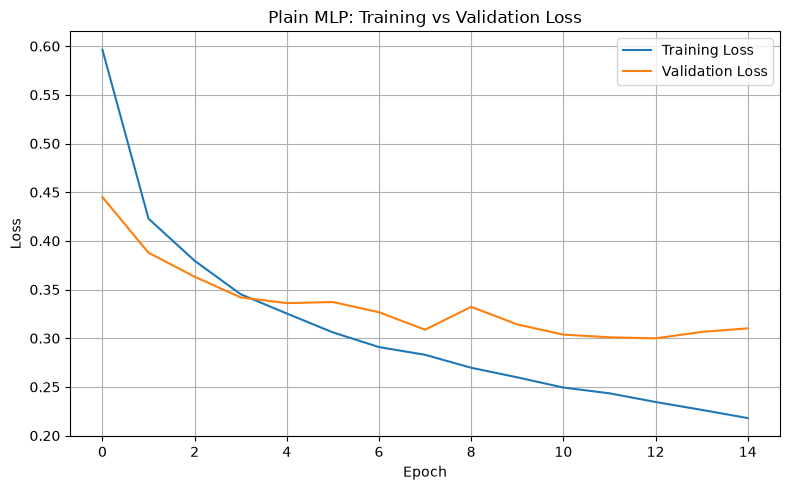

In [20]:
# Plot training and validation loss
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(plain_history["train_loss"], label="Training Loss")
ax.plot(plain_history["val_loss"], label="Validation Loss")

ax.set(xlabel="Epoch", ylabel="Loss", title="Plain MLP: Training vs Validation Loss")
ax.legend()
ax.grid(0.3)


plt.tight_layout()
plt.show()

In [21]:
# Compare baseline and MLP
print("Logistic Regression Accuracy:", round(lr_accuracy, 4))
print("Plain MLP Accuracy:", round(plain_history["best_val_accuracy"], 4))

Logistic Regression Accuracy: 0.8629
Plain MLP Accuracy: 0.8947


# **STAGE 3 — TUNE, ONE THING AT A TIME**

In [22]:
learning_rates = [0.0001, 0.001, 0.003, 0.01]

lr_results = {}
lr_histories = {}

for learning_rate in learning_rates:
    print("\nTesting Learning Rate:", learning_rate)

    model,history = train_model(X_train, y_train, X_val, y_val, hidden=256, depth=1, lr=learning_rate, epochs=10)

    lr_results[learning_rate] = history["best_val_accuracy"]
    lr_histories[learning_rate] = history


print("\nLearning Rate Results:")

for learning_rate, accuracy in lr_results.items():
    print(learning_rate, ":", round(accuracy, 4))


Testing Learning Rate: 0.0001
Epoch: 1/10 | Train Loss: 1.0592 | Val Loss: 0.6760 | Val Accuracy: 0.7746
Epoch: 2/10 | Train Loss: 0.6098 | Val Loss: 0.5474 | Val Accuracy: 0.8197
Epoch: 3/10 | Train Loss: 0.5290 | Val Loss: 0.4947 | Val Accuracy: 0.8357
Epoch: 4/10 | Train Loss: 0.4885 | Val Loss: 0.4711 | Val Accuracy: 0.8363
Epoch: 5/10 | Train Loss: 0.4642 | Val Loss: 0.4436 | Val Accuracy: 0.8497
Epoch: 6/10 | Train Loss: 0.4458 | Val Loss: 0.4287 | Val Accuracy: 0.8533
Epoch: 7/10 | Train Loss: 0.4309 | Val Loss: 0.4176 | Val Accuracy: 0.8587
Epoch: 8/10 | Train Loss: 0.4187 | Val Loss: 0.4101 | Val Accuracy: 0.8575
Epoch: 9/10 | Train Loss: 0.4088 | Val Loss: 0.4022 | Val Accuracy: 0.8622
Epoch: 10/10 | Train Loss: 0.4000 | Val Loss: 0.3943 | Val Accuracy: 0.8662

Testing Learning Rate: 0.001
Epoch: 1/10 | Train Loss: 0.5894 | Val Loss: 0.4374 | Val Accuracy: 0.8497
Epoch: 2/10 | Train Loss: 0.4179 | Val Loss: 0.3873 | Val Accuracy: 0.8629
Epoch: 3/10 | Train Loss: 0.3753 | Val

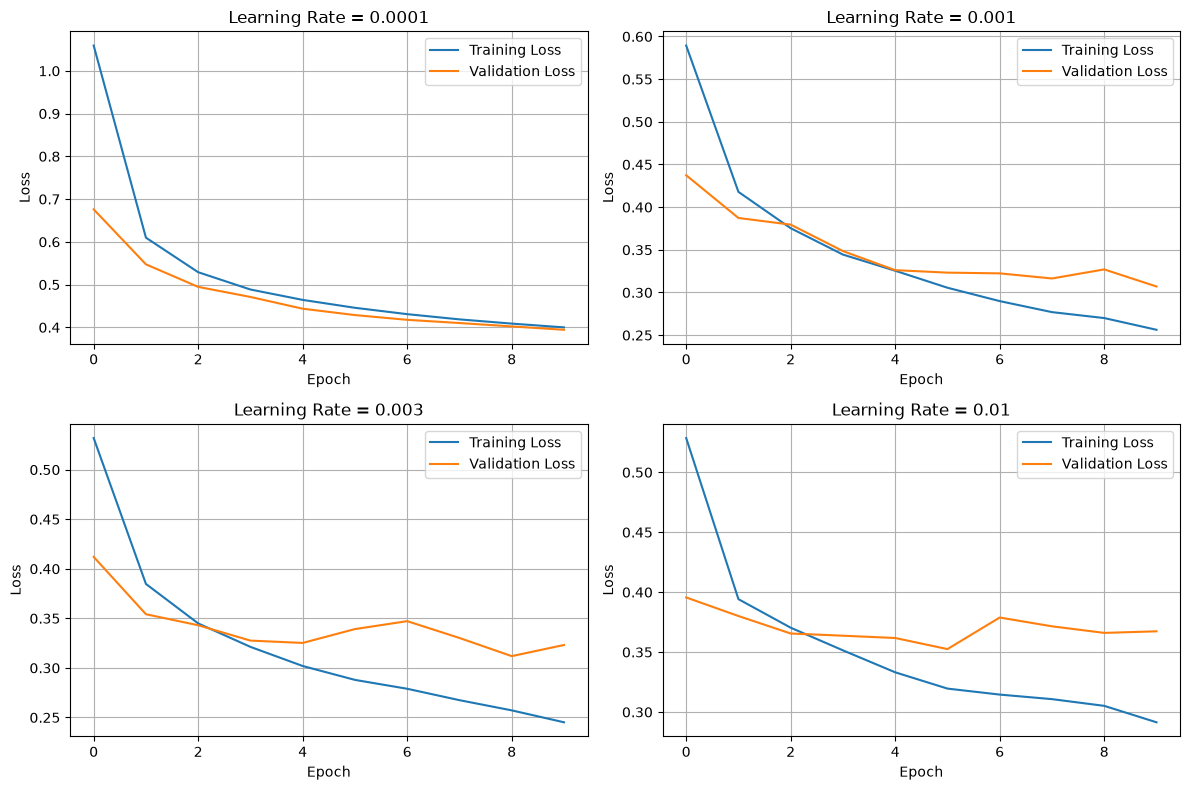

In [23]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

for i, learning_rate in enumerate(learning_rates):
    current_ax = ax.flat[i]
    history = lr_histories[learning_rate]

    current_ax.plot(history["train_loss"], label="Training Loss")
    current_ax.plot(history["val_loss"], label="Validation Loss")

    current_ax.set(xlabel="Epoch", ylabel="Loss", title=f"Learning Rate = {learning_rate}")
    current_ax.legend()
    current_ax.grid(0.3)


plt.tight_layout()
plt.show()

In [24]:
# select the best learning rate
best_lr = max(lr_results, key=lr_results.get)

print("Selected Learning Rate:", best_lr)
print("Validation Accuracy:", lr_results[best_lr])

Selected Learning Rate: 0.003
Validation Accuracy: 0.8927500247955322


In [25]:
# techniques one at a time, each measured against 
# Stage 2: dropout, weight decay, batch normalisation, a scheduler, early stopping, network width and depth.
# plain model configuration

plain_config = {
    "hidden": 256,
    "depth": 1,
    "lr": best_lr,
    "epochs": 12
}

# Different techniques, changed one at a time
experiments = [
    ("Plain MLP", {}),
    ("Dropout", {"dropout": 0.3}),
    ("Weight Decay", {"weight_decay": 0.0001}),
    ("Batch Normalisation", {"batch_norm": True}),
    ("Learning Rate Scheduler", {"use_scheduler": True}),
    ("Early Stopping", {"early_stopping": True}),
    ("Wider Network", {"hidden": 512}),
    ("Deeper Network", {"hidden": 256, "depth": 2})
]


experiment_results = []
experiment_histories = {}
experiment_models = {}
experiment_configs = {}

for experiment_name, changes in experiments:
    print()
    print("-" * 35)
    print("Experiment:", experiment_name)
    print("-" * 35)

    config = plain_config.copy()
    config.update(changes)

    model, history = train_model(X_train, y_train, X_val, y_val, **config)

    experiment_models[experiment_name] = model
    experiment_histories[experiment_name] = history
    experiment_configs[experiment_name] = config

    experiment_results.append({
        "Technique": experiment_name,
        "Best Validation Accuracy": history["best_val_accuracy"],
        "Best Validation Loss": history["best_val_loss"]
    })


experiment_table = pd.DataFrame(experiment_results)

experiment_table = experiment_table.sort_values(by="Best Validation Accuracy", ascending=False)

print(experiment_table)


-----------------------------------
Experiment: Plain MLP
-----------------------------------
Epoch: 1/12 | Train Loss: 0.5348 | Val Loss: 0.4030 | Val Accuracy: 0.8578
Epoch: 2/12 | Train Loss: 0.3869 | Val Loss: 0.3692 | Val Accuracy: 0.8649
Epoch: 3/12 | Train Loss: 0.3480 | Val Loss: 0.3565 | Val Accuracy: 0.8705
Epoch: 4/12 | Train Loss: 0.3239 | Val Loss: 0.3427 | Val Accuracy: 0.8760
Epoch: 5/12 | Train Loss: 0.3070 | Val Loss: 0.3532 | Val Accuracy: 0.8749
Epoch: 6/12 | Train Loss: 0.2872 | Val Loss: 0.3335 | Val Accuracy: 0.8795
Epoch: 7/12 | Train Loss: 0.2798 | Val Loss: 0.3292 | Val Accuracy: 0.8852
Epoch: 8/12 | Train Loss: 0.2640 | Val Loss: 0.3058 | Val Accuracy: 0.8910
Epoch: 9/12 | Train Loss: 0.2584 | Val Loss: 0.3122 | Val Accuracy: 0.8926
Epoch: 10/12 | Train Loss: 0.2488 | Val Loss: 0.3355 | Val Accuracy: 0.8853
Epoch: 11/12 | Train Loss: 0.2385 | Val Loss: 0.3219 | Val Accuracy: 0.8883
Epoch: 12/12 | Train Loss: 0.2336 | Val Loss: 0.3157 | Val Accuracy: 0.8895

-

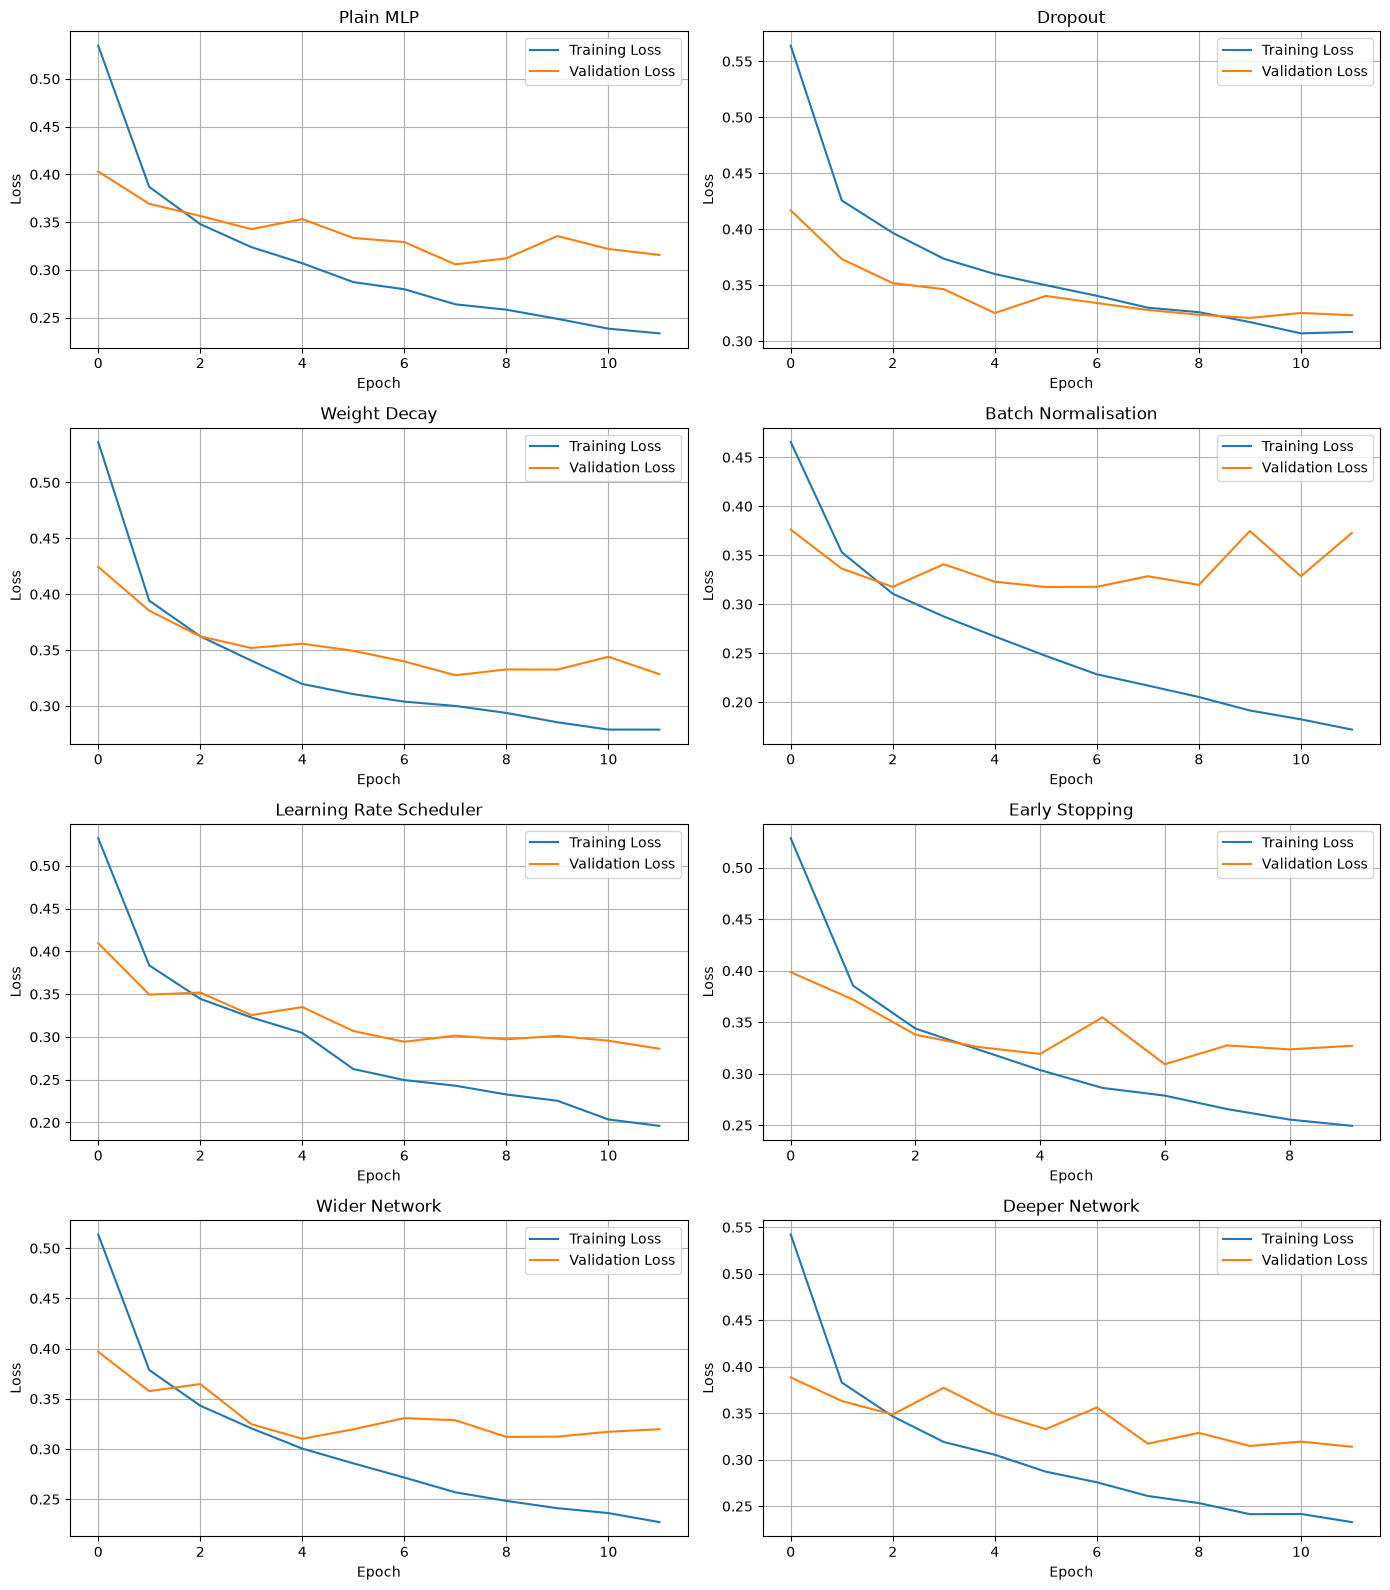

In [26]:
# Plot loss curves for all experiments
fig, ax = plt.subplots(4, 2, figsize=(14, 16))

for i, (experiment_name, history) in enumerate(experiment_histories.items()):
    current_ax = ax.flat[i]

    current_ax.plot(history["train_loss"], label="Training Loss")
    current_ax.plot(history["val_loss"], label="Validation Loss")

    current_ax.set(xlabel="Epoch", ylabel="Loss", title=experiment_name)
    current_ax.legend()
    current_ax.grid(0.3)

plt.tight_layout()
plt.show()

In [27]:
# Select the final model configuration
best_experiment = experiment_table.iloc[0]["Technique"]
final_config = experiment_configs[best_experiment]
final_model = experiment_models[best_experiment]


print("Selected Experiment:", best_experiment)
print("Selected Configuration:", final_config)

print("Best Validation Accuracy:", experiment_histories[best_experiment]["best_val_accuracy"])

Selected Experiment: Learning Rate Scheduler
Selected Configuration: {'hidden': 256, 'depth': 1, 'lr': 0.003, 'epochs': 12, 'use_scheduler': True}
Best Validation Accuracy: 0.9012500047683716


# **STAGE 4 — IS YOUR IMPROVEMENT REAL?**

In [29]:
from sklearn.model_selection import train_test_split
split_seeds = [11, 22, 33, 44, 55]

plain_split_scores = []
final_split_scores = []

for seed in split_seeds:
    print("\nTesting Split:", seed)

    # Create a new training and validation split
    Xtr, Xv, ytr, yv = train_test_split(X_train_original, y_train_original, test_size=0.20, random_state=seed,
                                       stratify=y_train_original)

    # Normalize the data
    Xtr = Xtr.astype(np.float32) / 255.0
    Xv = Xv.astype(np.float32) / 255.0

    # Train plain MLP
    plain_model_split, plain_history_split = train_model(Xtr, ytr, Xv, yv, hidden=256,
                                                        depth=1, lr=best_lr, epochs=8)
    plain_split_scores.append(plain_history_split["best_val_accuracy"])

    # Train Final MLP
    split_config = final_config.copy()
    split_config["epochs"] = 8
    
    final_model_split, final_history_split = train_model(Xtr, ytr, Xv, yv, **split_config)
    final_split_scores.append(final_history_split["best_val_accuracy"])


print("\nPlain MLP Score:", plain_split_scores)
print("Final MLP Score:", final_split_scores)


Testing Split: 11
Epoch: 1/8 | Train Loss: 0.5243 | Val Loss: 0.4201 | Val Accuracy: 0.8428
Epoch: 2/8 | Train Loss: 0.3834 | Val Loss: 0.3905 | Val Accuracy: 0.8572
Epoch: 3/8 | Train Loss: 0.3426 | Val Loss: 0.3628 | Val Accuracy: 0.8666
Epoch: 4/8 | Train Loss: 0.3205 | Val Loss: 0.3263 | Val Accuracy: 0.8823
Epoch: 5/8 | Train Loss: 0.3030 | Val Loss: 0.3236 | Val Accuracy: 0.8822
Epoch: 6/8 | Train Loss: 0.2884 | Val Loss: 0.3341 | Val Accuracy: 0.8790
Epoch: 7/8 | Train Loss: 0.2799 | Val Loss: 0.3128 | Val Accuracy: 0.8908
Epoch: 8/8 | Train Loss: 0.2649 | Val Loss: 0.3179 | Val Accuracy: 0.8862
Epoch: 1/8 | Train Loss: 0.5258 | Val Loss: 0.4339 | Val Accuracy: 0.8472
Epoch: 2/8 | Train Loss: 0.3829 | Val Loss: 0.3632 | Val Accuracy: 0.8673
Epoch: 3/8 | Train Loss: 0.3442 | Val Loss: 0.3539 | Val Accuracy: 0.8701
Epoch: 4/8 | Train Loss: 0.3171 | Val Loss: 0.3755 | Val Accuracy: 0.8593
Epoch: 5/8 | Train Loss: 0.3021 | Val Loss: 0.3294 | Val Accuracy: 0.8788
Epoch: 6/8 | Train 

In [36]:
print("PLAIN MLP")
print("-" * 10)
print("Minimum Accuracy:", min(plain_split_scores))
print("Maximum Accuracy:", max(plain_split_scores))
print("Average Accuracy:", np.mean(plain_split_scores))
print("Spread:", max(plain_split_scores) - min(plain_split_scores))

print("\nFINAL MLP")
print("-" * 10)
print("Minimum Accuracy:", min(final_split_scores))
print("Maximum Accuracy:", max(final_split_scores))
print("Average Accuracy:", np.mean(final_split_scores))
print("Spread:", max(final_split_scores) - min(final_split_scores))

PLAIN MLP
----------
Minimum Accuracy: 0.8800833225250244
Maximum Accuracy: 0.89083331823349
Average Accuracy: 0.8845833301544189
Spread: 0.010749995708465576

FINAL MLP
----------
Minimum Accuracy: 0.8861666917800903
Maximum Accuracy: 0.8914999961853027
Average Accuracy: 0.889466667175293
Spread: 0.005333304405212402


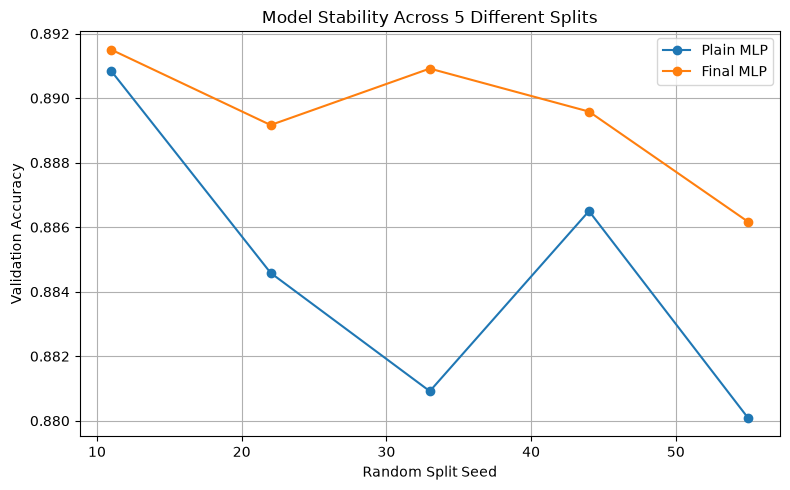

In [37]:
# Plot the results
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(split_seeds, plain_split_scores, marker="o", label="Plain MLP")
ax.plot(split_seeds, final_split_scores, marker="o", label="Final MLP")

ax.set(xlabel="Random Split Seed", ylabel="Validation Accuracy", title="Model Stability Across 5 Different Splits")
ax.legend()
ax.grid(0.3)

plt.tight_layout()
plt.show()

**Stability Observation :-**
- We compared the plain MLP and final MLP using Five different random splits.
- A smaller spreads means the model's performance is more consistent across different splits.
- The average validation accuracy helps us compare the overall performance of both models.

# **STAGE 5 — ERROR ANALYSIS**

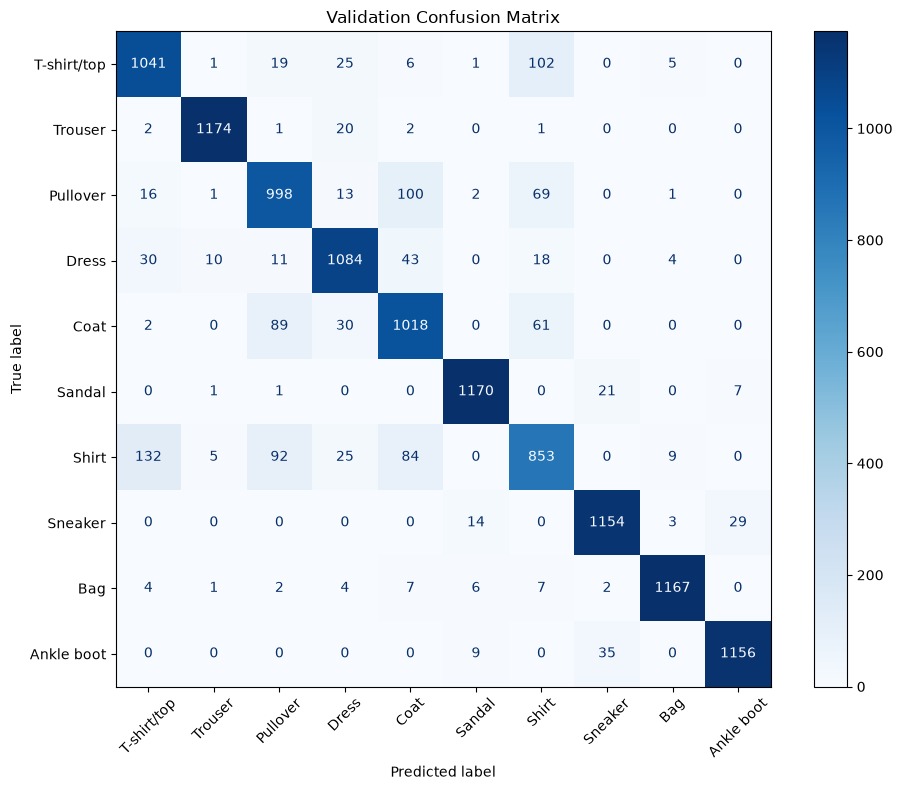

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Prepare validation data
X_val_tensor = torch.tensor(X_val.reshape(-1, 784), dtype=torch.float32).to(device)

# Predict using final model
final_model.eval()

with torch.no_grad():
    val_outputs = final_model(X_val_tensor)
    val_predictions = torch.argmax(val_outputs, dim=1).cpu().numpy()

# Create confusion matrix
cm = confusion_matrix(y_val, val_predictions)

# Display confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_name)
display.plot(cmap="Blues", xticks_rotation=45, ax=ax)

ax.set_title("Validation Confusion Matrix")

plt.tight_layout()
plt.show()

In [39]:
# find the most confused pair
# copy the confusion matrix
cm_without_diagonal = cm.copy()

# Remove correct prediction from consideration
np.fill_diagonal(cm_without_diagonal, 0)

# Find the largest confusion value
first_class, second_class = np.unravel_index(np.argmax(cm_without_diagonal), cm_without_diagonal.shape)

print("Most Confused Actual Class:", class_name[first_class])
print("Most Confused Predicted Class:", class_name[second_class])
print("Number of most confused images:", cm[first_class, second_class])

Most Confused Actual Class: Shirt
Most Confused Predicted Class: T-shirt/top
Number of most confused images: 132


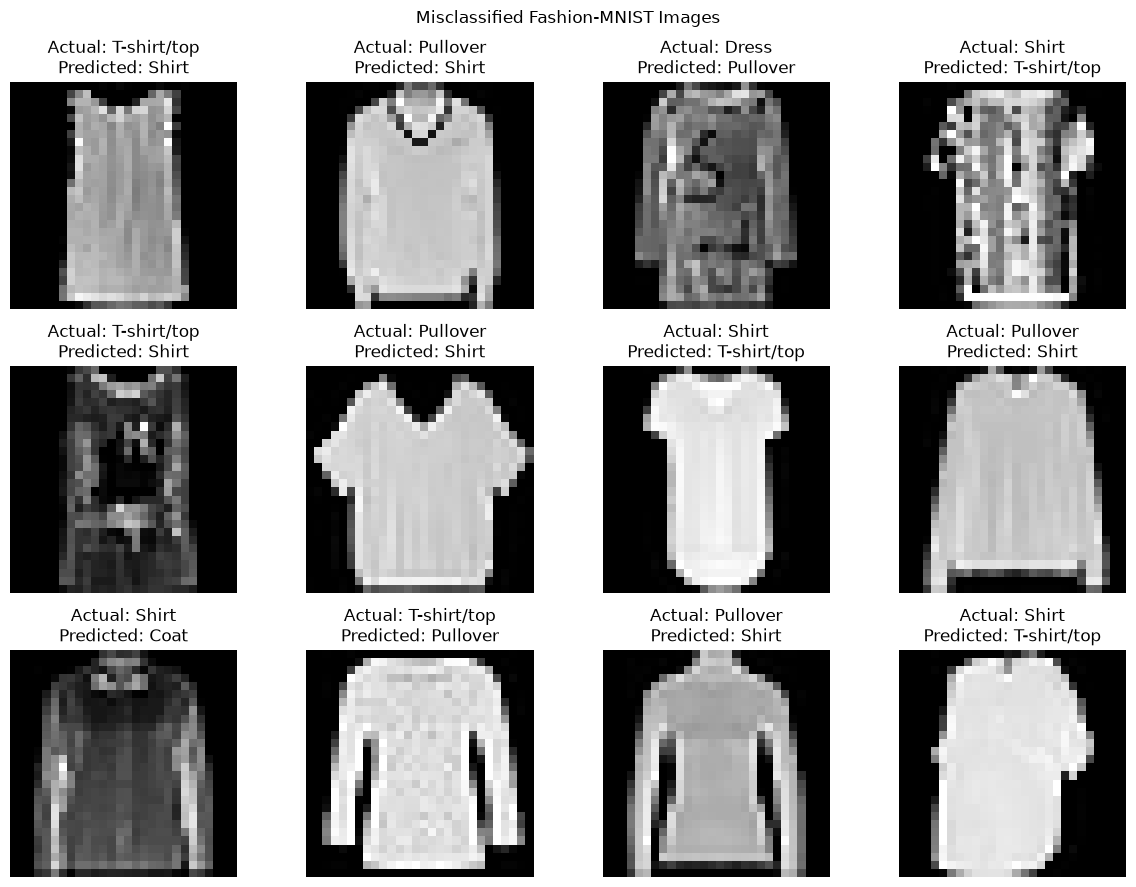

In [40]:
# Display atleast 12 wrong predictions
wrong_indices = np.where(val_predictions != y_val)[0]

# show maximum 12 incorrect images
number_to_show = min(12, len(wrong_indices))

fig, ax = plt.subplots(3, 4, figsize=(12, 9))

for i in range(number_to_show):
    current_ax = ax.flat[i]
    image_index = wrong_indices[i]

    current_ax.imshow(X_val[image_index].reshape(28, 28), cmap="gray")

    actual_label = class_name[int(y_val[image_index])]
    predicted_label = class_name[int(val_predictions[image_index])]

    current_ax.set_title(f"Actual: {actual_label}\nPredicted: {predicted_label}")

    current_ax.axis("off")


# Hide unused spaces if there are fewer than 12 images:
for i in range(number_to_show, 12):
    ax.flat[i].axis("off")


plt.suptitle("Misclassified Fashion-MNIST Images")
plt.tight_layout()
plt.show()

**Error Analysis Observation :-**
- The confusion matrix shows which clothing classes are difficult for the model to distinguish.
- Some classes have similar shapes and appearances. For example, Shirt and T-shirt/top can look similar in small grayscale images.
- Some of the model's mistakes may also be difficult for a human to identify because the images are only 28 × 28 pixels.

# **STAGE 6 — THE TEST SET, ONCE**

**Final Test Evaluation :-**
- We have completed model selection using the training and validation datasets.
- Now we will evaluate the selected final model on the official test dataset.
- We will not use the test results to change or tune the model.

In [43]:
import os
import numpy as np
import torch
from sklearn.metrics import accuracy_score, classification_report

# Load official test data
X_test = np.load(os.path.join(data_path, "Xte.npy"))
y_test = np.load(os.path.join(data_path, "yte.npy"))

# normalize test images
X_test = X_test.astype(np.float32) / 255.0


print("Test Images:", X_test.shape)
print("Test Labels:", y_test.shape)

Test Images: (10000, 784)
Test Labels: (10000,)


In [46]:
# Evaluate the final model
# Convert test images into tensors

X_test_tensor = torch.tensor(X_test.reshape(-1, 784), dtype=torch.float32).to(device)

final_model.eval()


with torch.no_grad():
    test_outputs = final_model(X_test_tensor)
    test_predictions = torch.argmax(test_outputs, dim=1).cpu().numpy()

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, test_predictions)


print("Final Test Accuracy:", round(test_accuracy, 4))
print("Final Test Accuracy(%):", round(test_accuracy * 100, 2), "%")

Final Test Accuracy: 0.89
Final Test Accuracy(%): 89.0 %


In [47]:
# Classification Report
print(classification_report(y_test, test_predictions, target_names=class_name))

              precision    recall  f1-score   support

 T-shirt/top       0.84      0.86      0.85      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.79      0.82      0.80      1000
       Dress       0.88      0.90      0.89      1000
        Coat       0.79      0.84      0.81      1000
      Sandal       0.98      0.96      0.97      1000
       Shirt       0.75      0.66      0.70      1000
     Sneaker       0.94      0.96      0.95      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.96      0.96      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



In [50]:
# Compare validation and test results:
validation_accuracy = experiment_histories[best_experiment]["best_val_accuracy"]

print("Validation Accuracy:", round(validation_accuracy, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Difference", round(abs(validation_accuracy - test_accuracy), 4))


if test_accuracy >= 0.89:
    print("\nTarget Achieved: 89% or higher.")
else:
    print("\nTarget not achieved. Report the actual result honestly.")

Validation Accuracy: 0.9013
Test Accuracy: 0.89
Difference 0.0113

Target Achieved: 89% or higher.


**Final Evaluation Observation :-**
- The final model was evaluated on the official test dataset only after completing model selection.
- We compared the validation and test accuracy to understand how well the model generalizes to unseen images.
- The target accuracy was 89.0%. We report the actual test accuracy obtained from the experiment.

# **STAGE 7 — PACKAGE IT**

In [51]:
import os
import torch

# Create project folders
os.makedirs("artifacts", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("notebooks", exist_ok=True)

# Save final model
torch.save(
    final_model.state_dict(),
    "models/fashion_mnist_mlp.pth"
)

print("Final model saved successfully.")

Final model saved successfully.


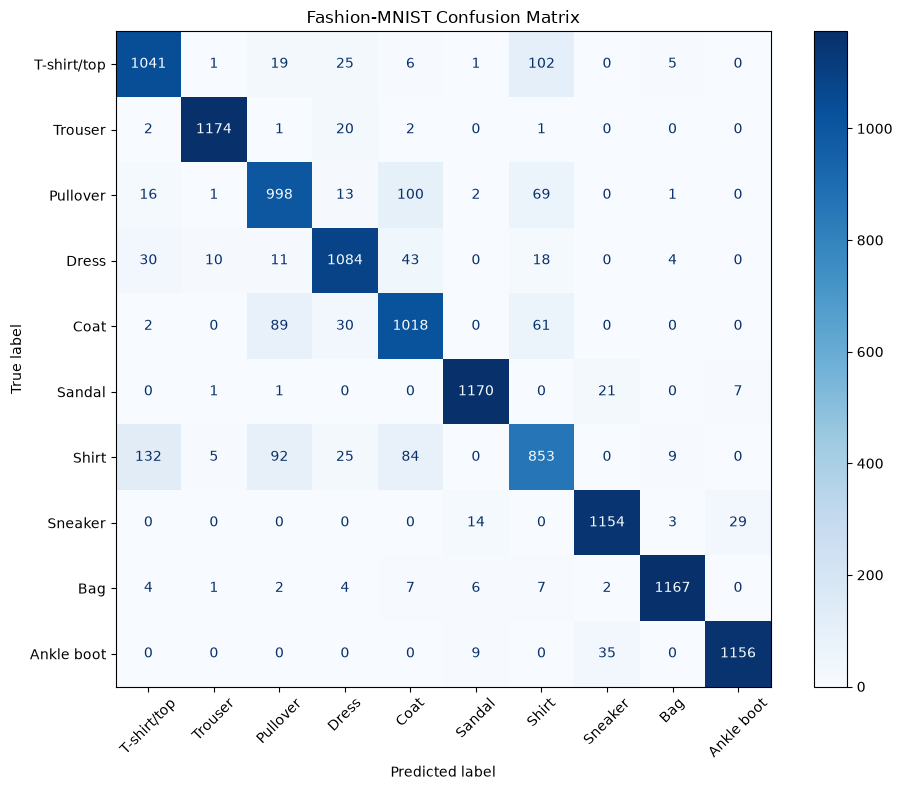

Confusion matrix saved successfully.


In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_name
)

display.plot(
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("Fashion-MNIST Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "artifacts/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully.")

In [53]:
experiment_table.to_csv(
    "artifacts/technique_comparison.csv",
    index=False
)

print("Technique comparison table saved.")

Technique comparison table saved.


In [54]:
decision_log = f"""
# Fashion-MNIST Decision Log

## 1. Baseline
Logistic Regression validation accuracy: {lr_accuracy:.4f}

## 2. Plain MLP
Plain MLP validation accuracy: {plain_history["best_val_accuracy"]:.4f}

## 3. Learning Rate
Selected learning rate: {best_lr}

## 4. Final Configuration
Selected experiment: {best_experiment}
Final configuration: {final_config}

## 5. Stability
Plain MLP average accuracy: {np.mean(plain_split_scores):.4f}
Plain MLP spread: {max(plain_split_scores) - min(plain_split_scores):.4f}

Final MLP average accuracy: {np.mean(final_split_scores):.4f}
Final MLP spread: {max(final_split_scores) - min(final_split_scores):.4f}

## 6. Final Test
Test accuracy: {test_accuracy:.4f}
Test accuracy percentage: {test_accuracy * 100:.2f}%

## 7. Decision
The final model was selected using validation performance.
The official test set was evaluated only once after model selection.
"""

with open("decision_log.md", "w") as file:
    file.write(decision_log)

print("Decision log saved.")

Decision log saved.


In [55]:
readme = f"""
# Fashion-MNIST Classification Using MLP

## Project Overview

This project classifies clothing images from the Fashion-MNIST dataset
using a Multi-Layer Perceptron (MLP).

Each image has dimensions of 28 x 28 pixels and belongs to one of
10 clothing categories.

## Dataset

- Training images: 60,000
- Test images: 10,000
- Image size: 28 x 28
- Input features: 784
- Classes: 10

## Models

- Logistic Regression baseline
- Plain Multi-Layer Perceptron
- Improved Multi-Layer Perceptron

## Results

- Logistic Regression validation accuracy: {lr_accuracy:.4f}
- Plain MLP validation accuracy: {plain_history["best_val_accuracy"]:.4f}
- Selected experiment: {best_experiment}
- Final validation accuracy: {validation_accuracy:.4f}
- Final test accuracy: {test_accuracy:.4f}
- Final test accuracy percentage: {test_accuracy * 100:.2f}%

## Confusion Matrix

![Confusion Matrix](artifacts/confusion_matrix.png)

## Technique Comparison

See `artifacts/technique_comparison.csv`.

## Decision Log

See `decision_log.md`.

## Model

Saved model: `models/fashion_mnist_mlp.pth`

## Important Note

The final test dataset was used only for the final evaluation.
Model selection and tuning were performed using validation data.
"""

with open("README.md", "w") as file:
    file.write(readme)

print("README created successfully.")

README created successfully.


In [56]:
from importlib.metadata import version

packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "scikit-learn",
    "torch"
]

with open("requirements.txt", "w") as file:

    for package in packages:
        package_version = version(package)
        file.write(f"{package}=={package_version}\n")

print("Pinned requirements saved.")

with open("requirements.txt", "r") as file:
    print(file.read())

Pinned requirements saved.
numpy==2.5.1
pandas==3.0.5
matplotlib==3.11.1
scikit-learn==1.9.0
torch==2.15.0



Fashion-MNIST-Project/  
│  
├── notebooks/  
│   └── Day50_Fashion_MNIST.ipynb  
│  
├── artifacts/  
│   ├── confusion_matrix.png  
│   └── technique_comparison.csv  
│  
├── models/  
│   └── fashion_mnist_mlp.pth  
│  
├── README.md   
├── decision_log.md  
└── requirements.txt  